# 16. Introduction to Object Detection
**Dataset note:** Local CIFAR-10 provides one image-level class label per image. It has no bounding-box or segmentation annotations. The drawn rectangle is for learning only, not a dataset annotation or model prediction.

## 1. Image classification

**Explanation:** Image classification assigns one label to the whole image. It does not say where an object is.

**Example:** A picture with a dog might receive the label `dog`.

In [1]:
image_label = "dog"
print("Whole-image label:", image_label)

Whole-image label: dog


**Interpretation:** The output tells us the image is classified as a dog, but gives no location or number of dogs.

## 2. Multi-class classification

**Explanation:** Multi-class classification means choosing one class from more than two possible classes. It still assigns one label to the whole image. CIFAR-10 has ten possible classes.

**Example:** Choose one label from airplane, automobile, or bird.

In [2]:
possible_classes = ["airplane", "automobile", "bird"]
predicted_class = "bird"
print("Choose one of", possible_classes)
print("Predicted class:", predicted_class)

Choose one of ['airplane', 'automobile', 'bird']
Predicted class: bird


**Interpretation:** `bird` is one choice from three possible classes. No box or object location is returned.

## 3. Object localization

**Explanation:** Object localization finds the location of one main object and gives its class. The location is usually shown as a bounding box.

**Example:** Find one dog and give its box.

In [3]:
main_object = "dog"
main_object_box = [4, 5, 27, 29]
print("Object:", main_object)
print("Box:", main_object_box)

Object: dog
Box: [4, 5, 27, 29]


**Interpretation:** The example identifies one dog and gives the rectangle around it. These values are made up for demonstration.

## 4. Object detection

**Explanation:** Object detection finds and labels multiple objects in one image. Each detected object gets its own box and class.

**Example:** Find a dog and a ball in the same picture.

In [4]:
detections = [
    {"class": "dog", "box": [4, 5, 27, 29]},
    {"class": "ball", "box": [20, 18, 30, 28]},
]
for item in detections:
    print(item["class"], "at", item["box"])

dog at [4, 5, 27, 29]
ball at [20, 18, 30, 28]


**Interpretation:** The result contains two objects, each with a separate class and box. This is a made-up example, not a model output.

## 5. Image segmentation

**Explanation:** Image segmentation assigns a class to each pixel. It can trace an object's shape more closely than a rectangular box.

**Example:** In this tiny map, `1` means object and `0` means background.

In [5]:
pixel_labels = [[0, 0, 0], [0, 1, 1], [0, 1, 1]]
print("Pixel labels:", pixel_labels)

Pixel labels: [[0, 0, 0], [0, 1, 1], [0, 1, 1]]


**Interpretation:** Each number labels one pixel; the `1` values mark the object area. The small grid is only a teaching example.

## 6. Bounding boxes

**Explanation:** A bounding box is a rectangle that surrounds an object. In this notebook, a box is written as `[x_min, y_min, x_max, y_max]`.

**Example:** `[4, 5, 27, 29]` is one rectangle in a 32 × 32 image.

In [6]:
box = [4, 5, 27, 29]
print("Bounding box:", box)

Bounding box: [4, 5, 27, 29]


**Interpretation:** The four numbers describe one rectangular region. This example box is illustrative, not a ground-truth label.

## 7. Box coordinates

**Explanation:** Coordinates measure position in the image. The origin `(0, 0)` is at the top-left. Here `x_min, y_min` is the box's top-left corner, and `x_max, y_max` is its bottom-right corner.

**Example:** Read the two corners from a box.

In [7]:
box = [4, 5, 27, 29]
x_min, y_min, x_max, y_max = box
print("Top-left:", (x_min, y_min))
print("Bottom-right:", (x_max, y_max))

Top-left: (4, 5)
Bottom-right: (27, 29)


**Interpretation:** The box begins at `(4, 5)` and ends at `(27, 29)`, measured from the image's top-left corner.

## 8. Class labels

**Explanation:** A class label is the name assigned to an object, such as `dog`, `car`, or `bird`.

**Example:** The box belongs to a dog.

In [8]:
class_label = "dog"
print("Object class:", class_label)

Object class: dog


**Interpretation:** The label tells us what the object is thought to be; it does not describe where it is.

## 9. Confidence score

**Explanation:** A confidence score is a model's score for a prediction. A higher score usually means the model favors that prediction more, but it is not a guarantee of correctness.

**Example:** A hypothetical model gives a dog prediction a score of `0.92`.

In [9]:
confidence = 0.92
print(f"Illustrative confidence: {confidence:.2f}")

Illustrative confidence: 0.92


**Interpretation:** `0.92` is the example model score. It does not mean there is a guaranteed 92% chance the prediction is correct.

## 10. A local CIFAR-10 image and an illustrative box

**Explanation:** This cell displays an image from the project's local CIFAR-10 data and its image-level class label. It draws an arbitrary red rectangle to show what a box looks like. CIFAR-10 has no box labels, so the red box is not guaranteed to surround the object.

**Example code:**

CIFAR-10 image label: cat


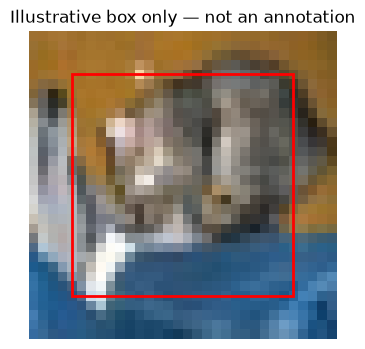

In [10]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from torchvision.datasets import CIFAR10
data_path = Path("data")
if not (data_path / "cifar-10-batches-py").is_dir():
    raise FileNotFoundError("Local CIFAR-10 data is missing from the data folder.")
test_data = CIFAR10(root=data_path, train=False, download=False)
image, label = test_data[0]
print("CIFAR-10 image label:", test_data.classes[label])
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(image)
ax.add_patch(Rectangle((4, 4), 23, 23, fill=False, edgecolor="red", linewidth=2))
ax.set_title("Illustrative box only — not an annotation")
ax.axis("off");

**Interpretation:** The printed class is the image-level CIFAR-10 label. The red box is just a drawing for learning and is not a correct annotated box or a model prediction.

## 11. Intersection over Union (IoU)

**Explanation:** IoU measures how much two boxes overlap. It is `intersection area / union area`. A score of `0` means no overlap; `1` means the boxes match exactly.

**Example:** Boxes `[2, 2, 8, 8]` and `[4, 4, 10, 10]` overlap by 16 square units. Each box has area 36, so the union is `36 + 36 - 16 = 56`, and IoU is `16 / 56`, about `0.29`.

In [11]:
def iou(box_a, box_b):
    left = max(box_a[0], box_b[0])
    top = max(box_a[1], box_b[1])
    right = min(box_a[2], box_b[2])
    bottom = min(box_a[3], box_b[3])
    intersection = max(0, right - left) * max(0, bottom - top)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    return intersection / (area_a + area_b - intersection)
print("IoU:", round(iou([2, 2, 8, 8], [4, 4, 10, 10]), 2))

IoU: 0.29


**Interpretation:** The result is `0.29`, so these boxes overlap somewhat but do not match closely. IoU can compare a predicted box with a reference box.

## 12. Non-Maximum Suppression (NMS)

**Explanation:** A detector may predict several overlapping boxes for the same object. NMS keeps the highest-confidence box and removes other boxes whose IoU with it is above a chosen threshold.

**Example:** The first two boxes below overlap heavily; the third is far away. The threshold is `0.5`.

In [12]:
boxes = [[0, 0, 10, 10], [1, 1, 11, 11], [20, 20, 30, 30]]
scores = [0.95, 0.80, 0.70]
order = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)
kept = []
while order:
    best = order.pop(0)
    kept.append(best)
    order = [i for i in order if iou(boxes[best], boxes[i]) <= 0.5]
print("Kept box indexes:", kept)

Kept box indexes: [0, 2]


**Interpretation:** NMS keeps box 0 because its confidence is highest, removes the overlapping box 1, and keeps box 2 because it is far away. This is a small teaching example, not a full detector.

## Summary

**Image → Objects → Bounding Boxes + Classes + Confidence**
